# HR Analytics — Job Change Prediction

## 1. Project Objective

The objective of this project is to analyze the HR Analytics: Job Change of Data Scientists dataset and develop machine-learning models to predict whether a candidate is likely to seek a job change.

This notebook focuses on:

- Understanding the structure and quality of the raw dataset
- Performing comprehensive exploratory data analysis
- Identifying missing values, duplicates, outliers, and unusual distributions
- Studying relationships between candidate characteristics and the target variable
- Applying justified data-cleaning and feature-engineering steps
- Producing a validated processed dataset for downstream machine-learning modeling

## 2. Imports and Configuration

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load Raw Dataset

In [2]:
PROJECT_ROOT = Path.cwd().parent

TRAIN_PATH = PROJECT_ROOT / "data" / "raw" / "aug_train.csv"
TEST_PATH = PROJECT_ROOT / "data" / "raw" / "aug_test.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Training dataset shape: {train_df.shape}")
print(f"Kaggle test dataset shape: {test_df.shape}")

Training dataset shape: (19158, 14)
Kaggle test dataset shape: (2129, 13)


In [3]:
train_df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [4]:
test_df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours
0,32403,city_41,0.827,Male,Has relevent experience,Full time course,Graduate,STEM,9,<10,NaN,1,21
1,9858,city_103,0.920,Female,Has relevent experience,no_enrollment,Graduate,STEM,5,NaN,Pvt Ltd,1,98
2,31806,city_21,0.624,Male,No relevent experience,no_enrollment,High School,NaN,<1,NaN,Pvt Ltd,never,15
3,27385,city_13,0.827,Male,Has relevent experience,no_enrollment,Masters,STEM,11,10/49,Pvt Ltd,1,39
4,27724,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,10000+,Pvt Ltd,>4,72


In [5]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nTraining target present:", "target" in train_df.columns)
print("Test target present:", "target" in test_df.columns)

Training columns:
['enrollee_id', 'city', 'city_development_index', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job', 'training_hours', 'target']

Test columns:
['enrollee_id', 'city', 'city_development_index', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job', 'training_hours']

Training target present: True
Test target present: False


In [6]:
train_df.shape

(19158, 14)

In [7]:
test_df.shape

(2129, 13)

In [8]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  str    
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  str    
 4   relevent_experience     19158 non-null  str    
 5   enrolled_university     18772 non-null  str    
 6   education_level         18698 non-null  str    
 7   major_discipline        16345 non-null  str    
 8   experience              19093 non-null  str    
 9   company_size            13220 non-null  str    
 10  company_type            13018 non-null  str    
 11  last_new_job            18735 non-null  str    
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), str(10)
memory usage: 3.

In [9]:
train_df["target"].value_counts(dropna=False)

target
0.0    14381
1.0     4777
Name: count, dtype: int64

In [10]:
# Check completely duplicated rows
duplicate_rows = train_df.duplicated().sum()

print(f"Duplicate rows: {duplicate_rows}")
print(f"Duplicate percentage: {duplicate_rows / len(train_df) * 100:.2f}%")

Duplicate rows: 0
Duplicate percentage: 0.00%


In [11]:
# Check duplicated enrollee IDs
duplicate_ids = train_df["enrollee_id"].duplicated().sum()

print(f"Duplicate enrollee IDs: {duplicate_ids}")

Duplicate enrollee IDs: 0


In [12]:
missing_summary = pd.DataFrame({
    "missing_count": train_df.isnull().sum(),
    "missing_percentage": train_df.isnull().mean() * 100
})

missing_summary = missing_summary.sort_values("missing_percentage", ascending=False)

missing_summary

,missing_count,missing_percentage
company_type,6140,32.049274
company_size,5938,30.994885
gender,4508,23.530640
major_discipline,2813,14.683161
education_level,460,2.401086
last_new_job,423,2.207955
enrolled_university,386,2.014824
experience,65,0.339284
enrollee_id,0,0.000000
city,0,0.000000


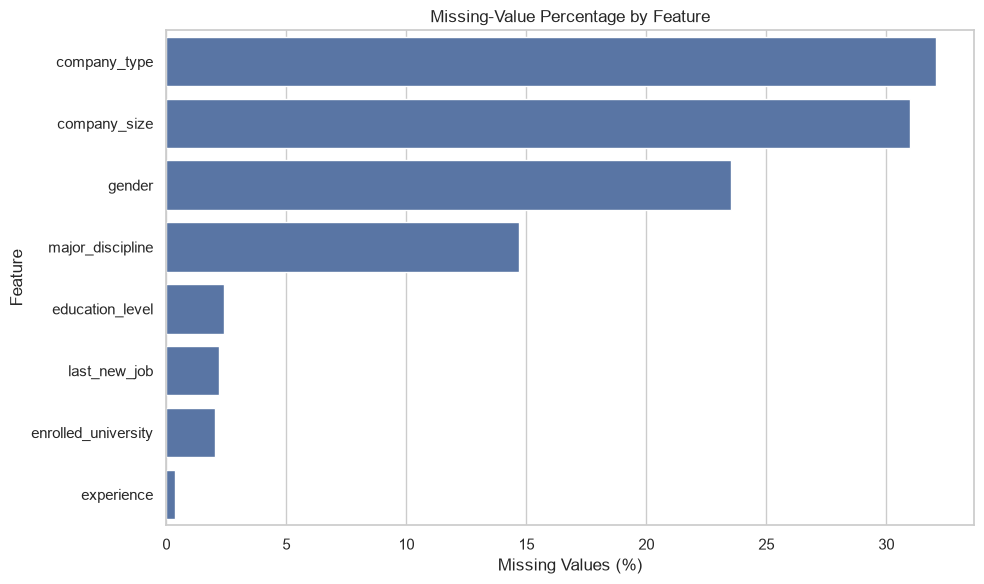

In [13]:
missing_plot = missing_summary[missing_summary["missing_count"] > 0].copy()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=missing_plot.reset_index(),
    x="missing_percentage",
    y="index"
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Missing-Value Percentage by Feature")
plt.tight_layout()
plt.show()

In [14]:
unique_summary = pd.DataFrame({
    "unique_count": train_df.nunique(dropna=False),
    "dtype": train_df.dtypes.astype(str)
}).sort_values("unique_count", ascending=False)

unique_summary

,unique_count,dtype
enrollee_id,19158,int64
training_hours,241,int64
city,123,str
city_development_index,93,float64
experience,23,str
company_size,9,str
last_new_job,7,str
company_type,7,str
major_discipline,7,str
education_level,6,str


In [15]:
categorical_columns = train_df.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

for column in categorical_columns:
    print(f"\n{'=' * 70}")
    print(f"{column}")
    print(f"{'=' * 70}")
    print(train_df[column].value_counts(dropna=False))

Categorical columns:
['city', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']

city
city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
            ... 
city_111       3
city_121       3
city_129       3
city_140       1
city_171       1
Name: count, Length: 123, dtype: int64

gender
gender
Male      13221
NaN        4508
Female     1238
Other       191
Name: count, dtype: int64

relevent_experience
relevent_experience
Has relevent experience    13792
No relevent experience      5366
Name: count, dtype: int64

enrolled_university
enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
NaN                   386
Name: count, dtype: int64

education_level
education_level
Graduate          11598
Masters            4361
High School        2017
NaN                 460
Phd                 414
Primary School

In [16]:
numeric_columns = train_df.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()

print("Numeric columns:")
print(numeric_columns)

train_df[numeric_columns].describe().T

Numeric columns:
['enrollee_id', 'city_development_index', 'training_hours', 'target']


,count,mean,std,min,25%,50%,75%,max
enrollee_id,19158.0,16875.358179,9616.292592,1.000,8554.25,16982.500,25169.75,33380.000
city_development_index,19158.0,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
training_hours,19158.0,65.366896,60.058462,1.000,23.00,47.000,88.00,336.000
target,19158.0,0.249348,0.432647,0.000,0.00,0.000,0.00,1.000


In [17]:
target_summary = train_df["target"].value_counts().sort_index()

target_percentage = train_df["target"].value_counts(normalize=True).sort_index() * 100

target_table = pd.DataFrame({
    "count": target_summary,
    "percentage": target_percentage
})

target_table

,count,percentage
target,,
0.0,14381,75.065247
1.0,4777,24.934753


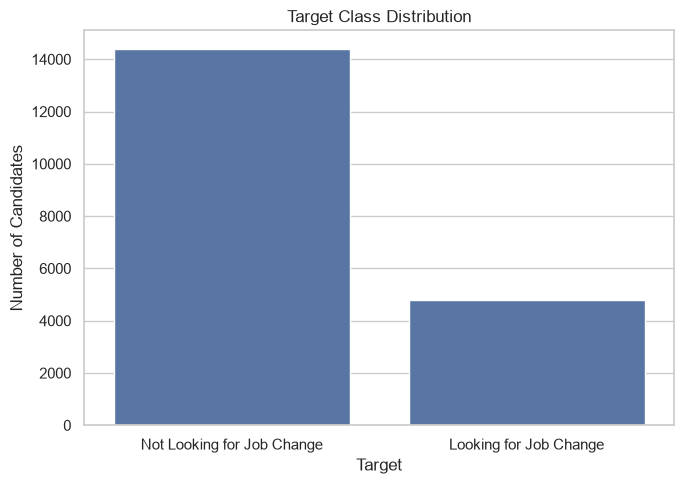

In [18]:
plt.figure(figsize=(7, 5))
sns.countplot(data=train_df,x="target")
plt.xlabel("Target")
plt.ylabel("Number of Candidates")
plt.title("Target Class Distribution")
plt.xticks([0, 1], ["Not Looking for Job Change", "Looking for Job Change"])
plt.tight_layout()
plt.show()

In [19]:
# Analyze whether missing values are associated with the target
missing_target_analysis = []

for column in train_df.columns:
    if train_df[column].isnull().sum() > 0:
        missing_mask = train_df[column].isnull()

        missing_target_analysis.append({
            "feature": column,
            "missing_count": missing_mask.sum(),
            "missing_percentage": missing_mask.mean() * 100,
            "target_rate_when_missing": train_df.loc[
                missing_mask, "target"
            ].mean() * 100,
            "target_rate_when_present": train_df.loc[
                ~missing_mask, "target"
            ].mean() * 100
        })

missing_target_df = pd.DataFrame(missing_target_analysis)
missing_target_df["target_rate_difference"] = missing_target_df["target_rate_when_missing"] - missing_target_df["target_rate_when_present"]

missing_target_df.sort_values(
    "target_rate_difference",
    key=abs,
    ascending=False
)

,feature,missing_count,missing_percentage,target_rate_when_missing,target_rate_when_present,target_rate_difference
5,company_size,5938,30.994885,40.586056,17.904690,22.681366
6,company_type,6140,32.049274,38.827362,18.382240,20.445122
7,last_new_job,423,2.207955,36.406619,24.675741,11.730879
4,experience,65,0.339284,35.384615,24.899178,10.485438
0,gender,4508,23.530640,30.811890,23.126280,7.685610
1,enrolled_university,386,2.014824,31.865285,24.792244,7.073041
3,major_discipline,2813,14.683161,19.516530,25.867238,-6.350707
2,education_level,460,2.401086,22.608696,24.991978,-2.383282


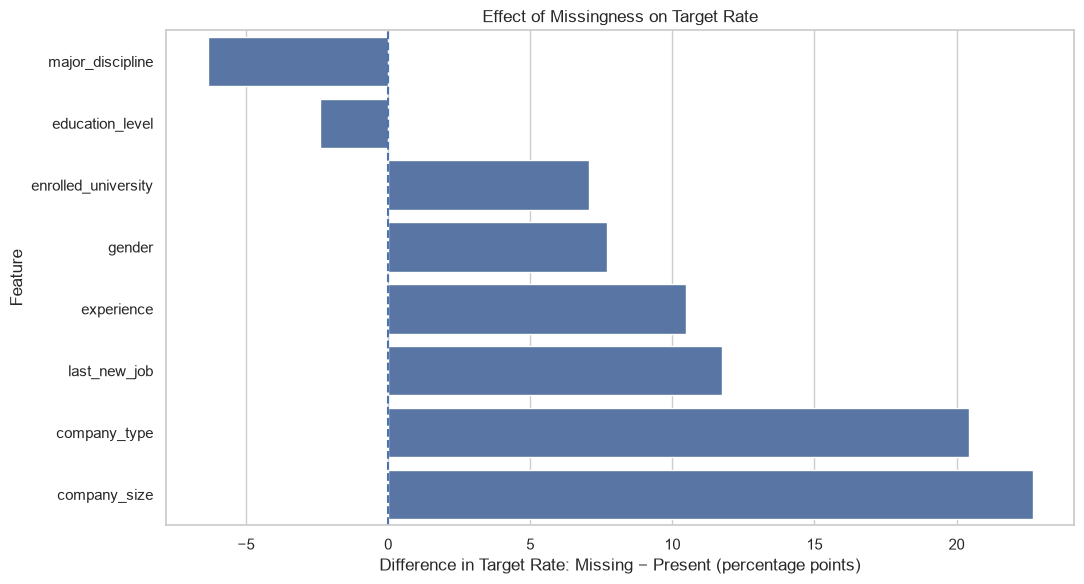

In [20]:
plt.figure(figsize=(11, 6))
plot_data = missing_target_df.sort_values("target_rate_difference")
sns.barplot(data=plot_data,x="target_rate_difference",y="feature")
plt.axvline(0, linestyle="--")
plt.xlabel("Difference in Target Rate: Missing − Present (percentage points)")
plt.ylabel("Feature")
plt.title("Effect of Missingness on Target Rate")
plt.tight_layout()
plt.show()

In [21]:
experience_target = (
    train_df
    .groupby("experience", dropna=False)["target"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

experience_target

,count,mean
experience,,
<1,522,0.454023
1,549,0.424408
NaN,65,0.353846
3,1354,0.353028
2,1127,0.331854
4,1403,0.325731
7,1028,0.294747
5,1430,0.288112
6,1216,0.282072


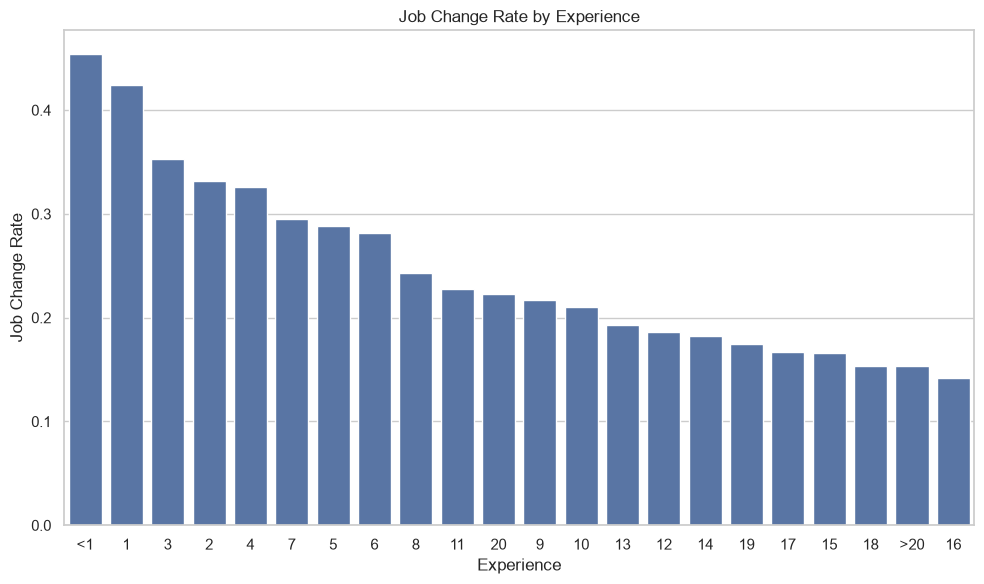

In [22]:
plt.figure(figsize=(10, 6))
sns.barplot(data=experience_target.reset_index(),x="experience",y="mean")
plt.xlabel("Experience")
plt.ylabel("Job Change Rate")
plt.title("Job Change Rate by Experience")
plt.tight_layout()
plt.show()

In [23]:
last_job_target = train_df.groupby("last_new_job", dropna=False)["target"].agg(["count", "mean"])
last_job_target

,count,mean
last_new_job,,
1,8040,0.264303
2,2900,0.241379
3,1024,0.225586
4,1029,0.221574
>4,3290,0.182371
never,2452,0.301387
NaN,423,0.364066


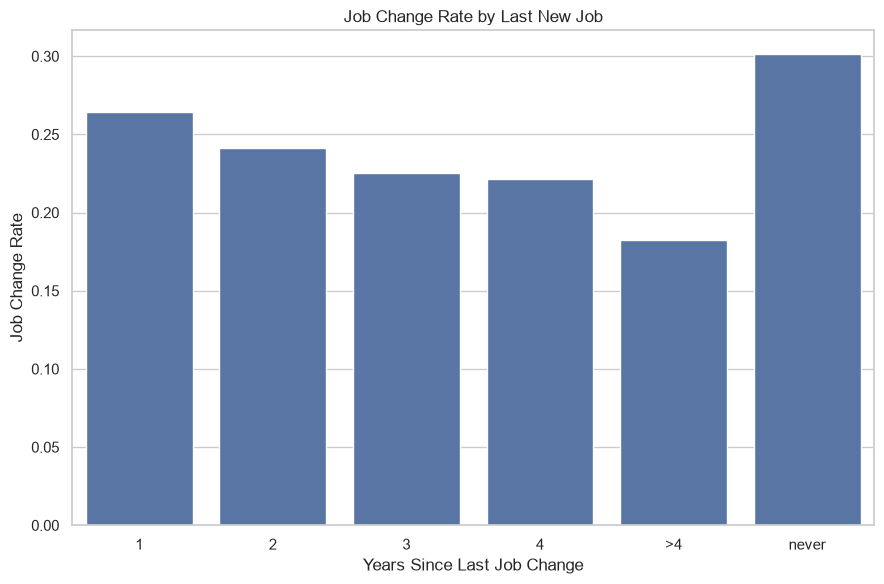

In [24]:
plt.figure(figsize=(9, 6))
sns.barplot(data=last_job_target.reset_index(),x="last_new_job",y="mean")
plt.xlabel("Years Since Last Job Change")
plt.ylabel("Job Change Rate")
plt.title("Job Change Rate by Last New Job")
plt.tight_layout()
plt.show()

In [25]:
categorical_target_summary = []

for column in categorical_columns:
    if column == "city":
        continue

    grouped = (
        train_df
        .groupby(column, dropna=False)["target"]
        .agg(["count", "mean"])
        .reset_index()
    )

    for _, row in grouped.iterrows():
        categorical_target_summary.append({
            "feature": column,
            "category": row[column],
            "count": row["count"],
            "target_rate": row["mean"] * 100
        })

categorical_target_df = pd.DataFrame(
    categorical_target_summary
)

categorical_target_df

,feature,category,count,target_rate
0,gender,Female,1238,26.332795
1,gender,Male,13221,22.781938
2,gender,Other,191,26.178010
3,gender,NaN,4508,30.811890
4,relevent_experience,Has relevent experience,13792,21.468968
5,relevent_experience,No relevent experience,5366,33.842713
6,enrolled_university,Full time course,3757,38.088901
7,enrolled_university,Part time course,1198,25.208681
8,enrolled_university,no_enrollment,13817,21.140624
9,enrolled_university,NaN,386,31.865285


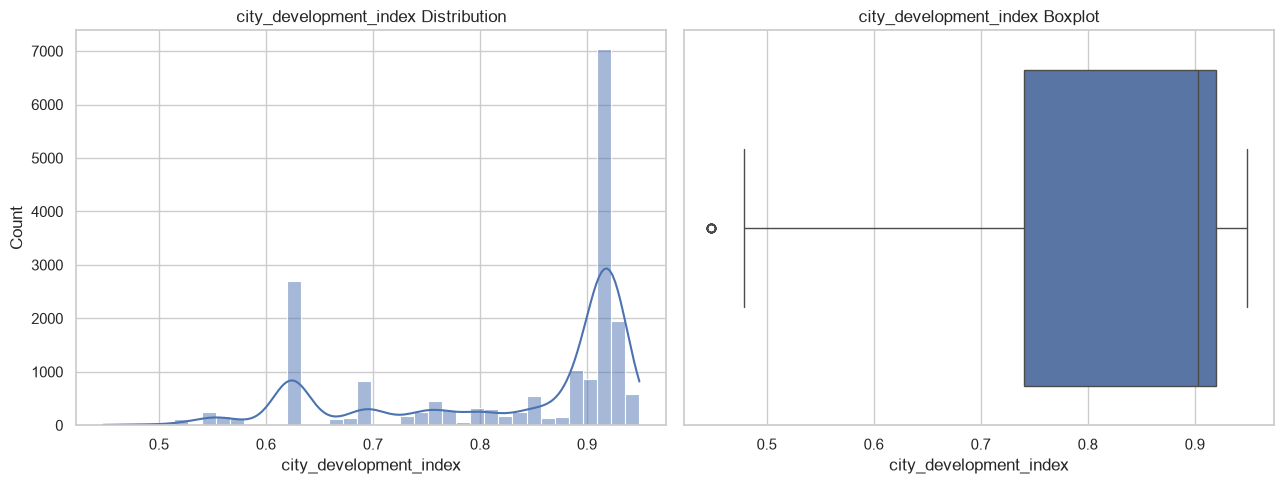

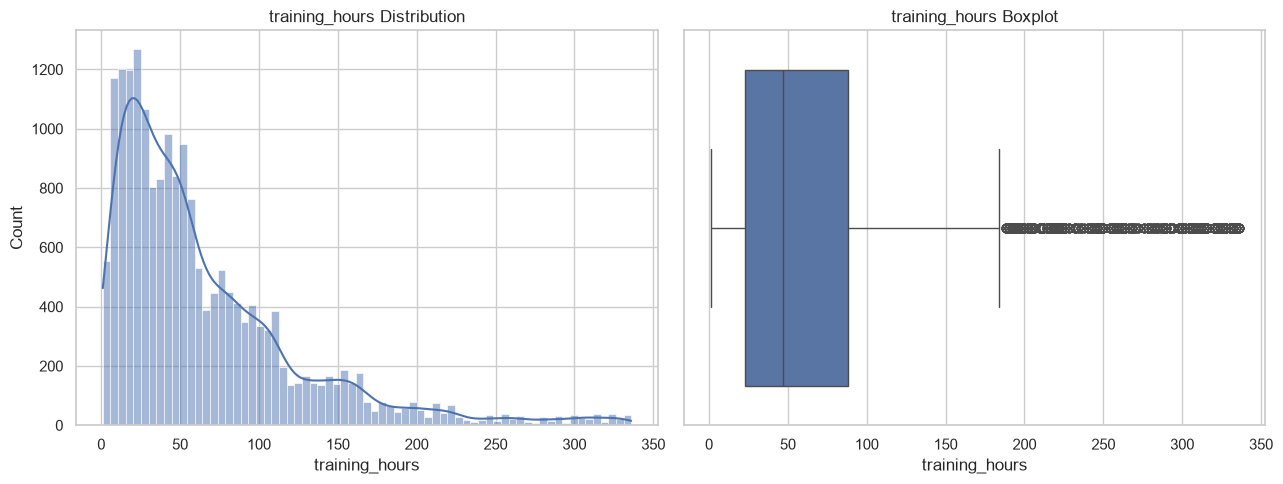

In [26]:
numeric_features = ["city_development_index","training_hours"]

for column in numeric_features:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    sns.histplot(data=train_df,x=column,kde=True,ax=axes[0])
    axes[0].set_title(f"{column} Distribution")
    sns.boxplot(data=train_df,x=column,ax=axes[1])
    axes[1].set_title(f"{column} Boxplot")

    plt.tight_layout()
    plt.show()

In [27]:
numeric_analysis = train_df[numeric_features].describe().T
numeric_analysis["skewness"] = train_df[numeric_features].skew()
numeric_analysis

,count,mean,std,min,25%,50%,75%,max,skewness
city_development_index,19158.0,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949,-0.995428
training_hours,19158.0,65.366896,60.058462,1.000,23.00,47.000,88.00,336.000,1.819237


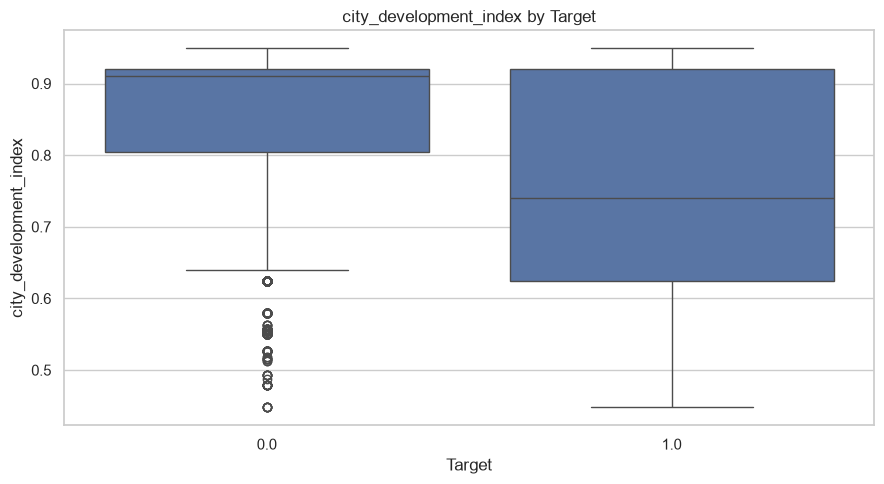

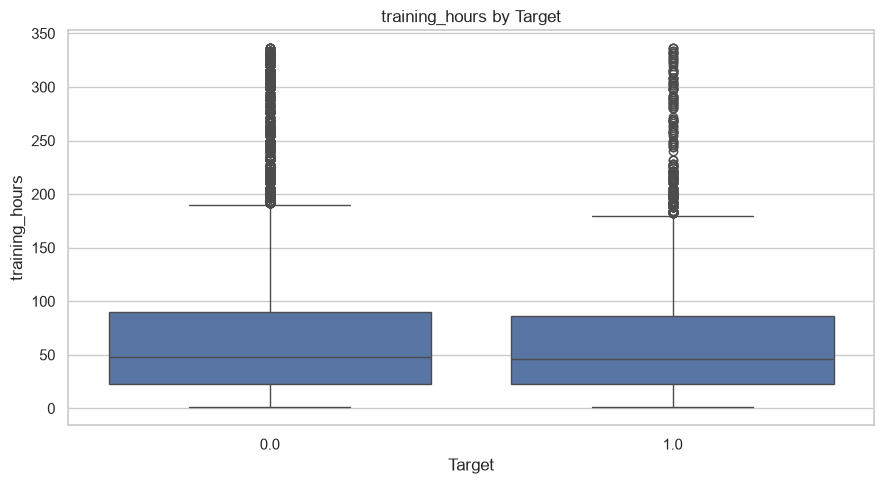

In [28]:
for column in numeric_features:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=train_df,x="target",y=column)
    plt.title(f"{column} by Target")
    plt.xlabel("Target")
    plt.tight_layout()
    plt.show()

In [29]:
city_frequency = train_df["city"].value_counts().rename_axis("city").reset_index(name="count")
city_frequency.head(20)

,city,count
0,city_103,4355
1,city_21,2702
2,city_16,1533
3,city_114,1336
4,city_160,845
5,city_136,586
6,city_67,431
7,city_75,305
8,city_102,304
9,city_104,301


In [30]:
city_frequency["count"].describe()

count     123.000000
mean      155.756098
std       493.999276
min         1.000000
25%        13.000000
50%        31.000000
75%       104.000000
max      4355.000000
Name: count, dtype: float64

In [31]:
rare_city_counts = {
    "1-5": ((city_frequency["count"] >= 1) & (city_frequency["count"] <= 5)).sum(),
    "6-10": ((city_frequency["count"] >= 6) & (city_frequency["count"] <= 10)).sum(),
    "11-50": ((city_frequency["count"] >= 11) & (city_frequency["count"] <= 50)).sum(),
    "51-100": ((city_frequency["count"] >= 51) & (city_frequency["count"] <= 100)).sum(),
    ">100": (city_frequency["count"] > 100).sum()
}

pd.Series(rare_city_counts)

1-5       14
6-10      14
11-50     43
51-100    18
>100      34
dtype: int64

In [32]:
city_target = train_df.groupby("city")["target"].agg(["count", "mean"]).sort_values("count", ascending=False)
city_target["target_rate"] = city_target["mean"] * 100
city_target.head(20)

,count,mean,target_rate
city,,,
city_103,4355,0.213088,21.308840
city_21,2702,0.591044,59.104367
city_16,1533,0.116765,11.676451
city_114,1336,0.099551,9.955090
city_160,845,0.235503,23.550296
city_136,586,0.104096,10.409556
city_67,431,0.132251,13.225058
city_75,305,0.101639,10.163934
city_102,304,0.171053,17.105263


In [33]:
city_target.sort_values("count").head(20)

,count,mean,target_rate
city,,,
city_171,1,1.000000,100.000000
city_140,1,0.000000,0.000000
city_121,3,0.333333,33.333333
city_111,3,0.000000,0.000000
city_129,3,0.000000,0.000000
city_82,4,0.000000,0.000000
city_166,4,0.250000,25.000000
city_25,4,0.500000,50.000000
city_18,4,0.250000,25.000000


In [34]:
train_df["development_index_bin"] = pd.cut(train_df["city_development_index"],bins=10)

development_target = train_df.groupby("development_index_bin", observed=True)["target"].agg(["count", "mean"])
development_target["target_rate"] = development_target["mean"] * 100
development_target

,count,mean,target_rate
development_index_bin,,,
"(0.447, 0.498]",63,0.587302,58.730159
"(0.498, 0.548]",115,0.573913,57.391304
"(0.548, 0.598]",547,0.579525,57.952468
"(0.598, 0.648]",2750,0.583273,58.327273
"(0.648, 0.698]",1081,0.277521,27.752081
"(0.698, 0.749]",448,0.263393,26.339286
"(0.749, 0.799]",962,0.239085,23.908524
"(0.799, 0.849]",987,0.150963,15.096251
"(0.849, 0.899]",2380,0.133193,13.319328


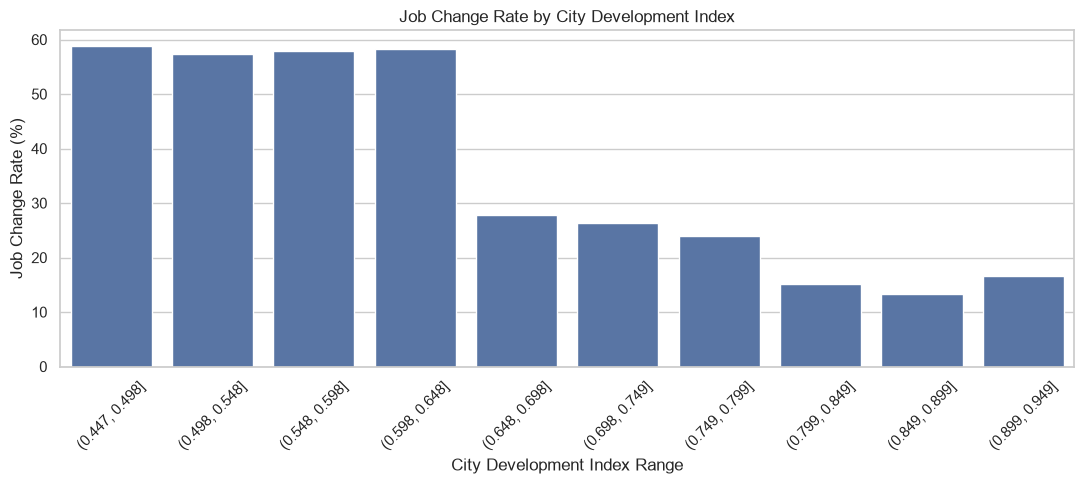

In [35]:
plt.figure(figsize=(11, 5))
sns.barplot(data=development_target.reset_index(),x="development_index_bin",y="target_rate")
plt.xticks(rotation=45)
plt.xlabel("City Development Index Range")
plt.ylabel("Job Change Rate (%)")
plt.title("Job Change Rate by City Development Index")
plt.tight_layout()
plt.show()

## Feature Correlation and Relationship

In [36]:
# Prepare temporary numeric versions for EDA only

eda_df = train_df.copy()

experience_map = {
    "<1": 0,
    "1": 1,
    "2": 2,
    "3": 3,
    "4": 4,
    "5": 5,
    "6": 6,
    "7": 7,
    "8": 8,
    "9": 9,
    "10": 10,
    "11": 11,
    "12": 12,
    "13": 13,
    "14": 14,
    "15": 15,
    "16": 16,
    "17": 17,
    "18": 18,
    "19": 19,
    "20": 20,
    ">20": 21
}

last_job_map = {
    "never": 0,
    "1": 1,
    "2": 2,
    "3": 3,
    "4": 4,
    ">4": 5
}

eda_df["experience_numeric"] = (
    eda_df["experience"].map(experience_map)
)

eda_df["last_new_job_numeric"] = (
    eda_df["last_new_job"].map(last_job_map)
)

correlation_columns = [
    "city_development_index",
    "training_hours",
    "experience_numeric",
    "last_new_job_numeric",
    "target"
]

correlation_matrix = eda_df[correlation_columns].corr()

correlation_matrix

,city_development_index,training_hours,experience_numeric,last_new_job_numeric,target
city_development_index,1.000000,0.001920,0.333967,0.188984,-0.341665
training_hours,0.001920,1.000000,0.000908,-0.006276,-0.021577
experience_numeric,0.333967,0.000908,1.000000,0.479033,-0.176724
last_new_job_numeric,0.188984,-0.006276,0.479033,1.000000,-0.082607
target,-0.341665,-0.021577,-0.176724,-0.082607,1.000000


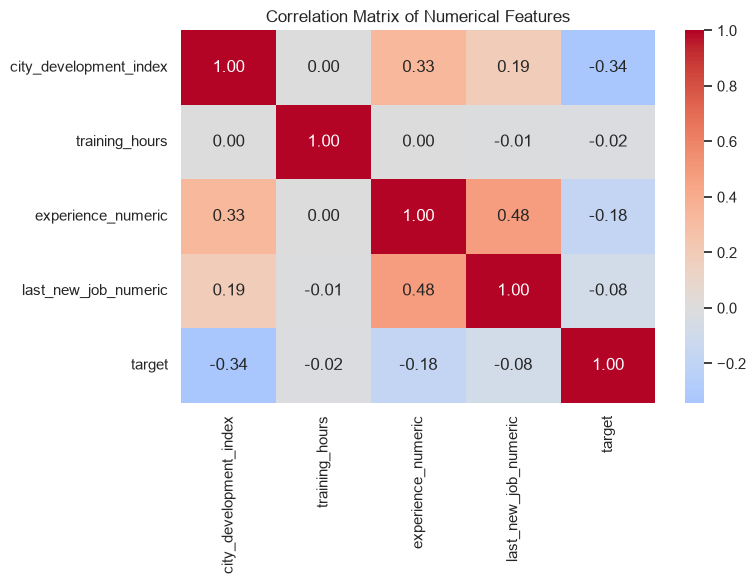

In [37]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap="coolwarm",center=0)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

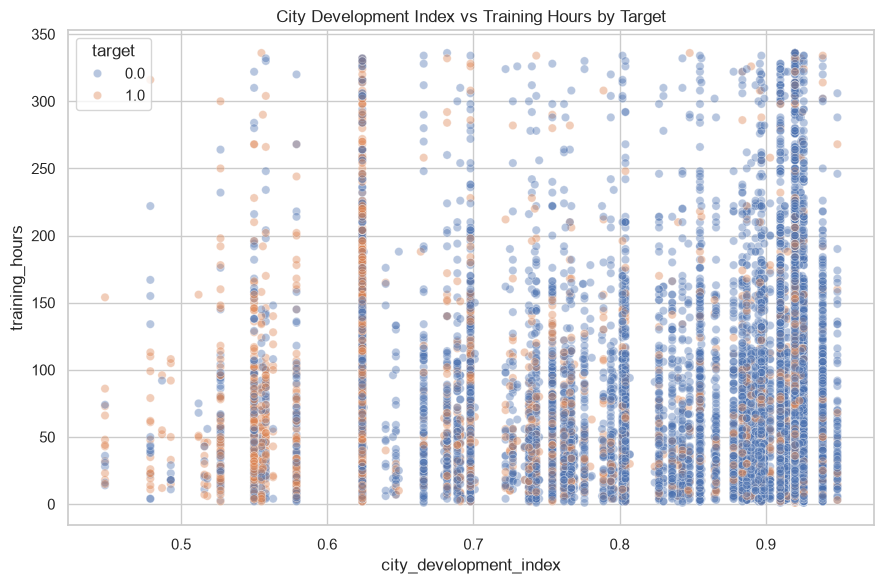

In [39]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=train_df,x="city_development_index",y="training_hours",hue="target",alpha=0.4)
plt.title("City Development Index vs Training Hours by Target")
plt.tight_layout()
plt.show()

Based on the EDA findings, the dataset will be cleaned using the following decisions:

- Keep `enrollee_id` for traceability, but exclude it from model features later.
- Group rare cities and one-hot encode them during model preprocessing.
- Preserve missing categorical values as `Unknown`.
- Convert `experience` and `last_new_job` into ordered numerical features.
- Add missing-value indicators for `experience` and `last_new_job`.
- Keep `city_development_index` and `training_hours` as numerical features.
- Keep the target variable unchanged.

In [40]:
# Create a separate dataframe so the original raw data remains unchanged.
clean_df = train_df.copy()

print(f"Original shape: {clean_df.shape}")

Original shape: (19158, 15)


In [41]:
ID_COLUMN = "enrollee_id"
TARGET_COLUMN = "target"

print(f"ID column: {ID_COLUMN}")
print(f"Target column: {TARGET_COLUMN}")

ID column: enrollee_id
Target column: target


In [42]:
categorical_columns = [
    "city",
    "gender",
    "relevent_experience",
    "enrolled_university",
    "education_level",
    "major_discipline",
    "company_size",
    "company_type",
]

for column in categorical_columns:
    clean_df[column] = clean_df[column].fillna("Unknown")

print("Categorical missing values replaced with 'Unknown'.")

Categorical missing values replaced with 'Unknown'.


In [43]:
clean_df[categorical_columns].isna().sum()

city                   0
gender                 0
relevent_experience    0
enrolled_university    0
education_level        0
major_discipline       0
company_size           0
company_type           0
dtype: int64

In [44]:
CITY_MIN_FREQUENCY = 10

city_counts = clean_df["city"].value_counts()
rare_cities = city_counts[city_counts < CITY_MIN_FREQUENCY].index
clean_df["city"] = clean_df["city"].where(~clean_df["city"].isin(rare_cities),"Other")

print(f"Original number of city categories: {len(city_counts)}")
print(f"Rare cities grouped: {len(rare_cities)}")
print(f"Final number of city categories: {clean_df['city'].nunique()}")

Original number of city categories: 123
Rare cities grouped: 24
Final number of city categories: 100


In [45]:
clean_df["experience_missing"] = clean_df["experience"].isna().astype(int)
clean_df["experience_numeric"] = clean_df["experience"].map(experience_map)
print(clean_df[["experience", "experience_numeric", "experience_missing"]].head(10))

  experience  experience_numeric  experience_missing
0        >20                21.0                   0
1         15                15.0                   0
2          5                 5.0                   0
3         <1                 0.0                   0
4        >20                21.0                   0
5         11                11.0                   0
6          5                 5.0                   0
7         13                13.0                   0
8          7                 7.0                   0
9         17                17.0                   0


In [47]:
clean_df["last_new_job_missing"] = clean_df["last_new_job"].isna().astype(int)
clean_df["last_new_job_numeric"] = clean_df["last_new_job"].map(last_job_map)

print(clean_df[["last_new_job", "last_new_job_numeric", "last_new_job_missing"]].head(10))

  last_new_job  last_new_job_numeric  last_new_job_missing
0            1                   1.0                     0
1           >4                   5.0                     0
2        never                   0.0                     0
3        never                   0.0                     0
4            4                   4.0                     0
5            1                   1.0                     0
6            1                   1.0                     0
7           >4                   5.0                     0
8            1                   1.0                     0
9           >4                   5.0                     0


In [48]:
clean_df = clean_df.drop(columns=["experience", "last_new_job"])
print("Original experience and last_new_job columns removed.")

Original experience and last_new_job columns removed.


In [58]:
# Remove EDA-only columns that should not be used for modeling.
EDA_ONLY_COLUMNS = [
    "development_index_bin"
]
clean_df = clean_df.drop(columns=EDA_ONLY_COLUMNS, errors="ignore")
print("EDA-only columns removed.")
print("Current shape:", clean_df.shape)

EDA-only columns removed.
Current shape: (19158, 16)


In [59]:
print("Cleaned dataset columns:")
for i, column in enumerate(clean_df.columns, start=1):
    print(f"{i:2}. {column}")

Cleaned dataset columns:
 1. enrollee_id
 2. city
 3. city_development_index
 4. gender
 5. relevent_experience
 6. enrolled_university
 7. education_level
 8. major_discipline
 9. company_size
10. company_type
11. training_hours
12. target
13. experience_missing
14. experience_numeric
15. last_new_job_missing
16. last_new_job_numeric


In [62]:
missing_summary = clean_df.isna().sum().sort_values(ascending=False)
missing_summary[missing_summary > 0]

last_new_job_numeric    423
experience_numeric       65
dtype: int64

In [63]:
categorical_columns_clean = [
    "city",
    "gender",
    "relevent_experience",
    "enrolled_university",
    "education_level",
    "major_discipline",
    "company_size",
    "company_type",
]

categorical_missing = clean_df[categorical_columns_clean].isna().sum()
print(categorical_missing)

city                   0
gender                 0
relevent_experience    0
enrolled_university    0
education_level        0
major_discipline       0
company_size           0
company_type           0
dtype: int64


In [64]:
print("Target distribution:")
print(clean_df["target"].value_counts())

print("\nTarget proportions:")
print(clean_df["target"].value_counts(normalize=True))

Target distribution:
target
0.0    14381
1.0     4777
Name: count, dtype: int64

Target proportions:
target
0.0    0.750652
1.0    0.249348
Name: proportion, dtype: float64


In [65]:
print("Experience numeric summary:")
print(clean_df["experience_numeric"].describe())

print("\nExperience missing:")
print(clean_df["experience_missing"].value_counts())

print("\nLast new job numeric summary:")
print(clean_df["last_new_job_numeric"].describe())

print("\nLast new job missing:")
print(clean_df["last_new_job_missing"].value_counts())

Experience numeric summary:
count    19093.000000
mean        10.100141
std          6.777024
min          0.000000
25%          4.000000
50%          9.000000
75%         16.000000
max         21.000000
Name: experience_numeric, dtype: float64

Experience missing:
experience_missing
0    19093
1       65
Name: count, dtype: int64

Last new job numeric summary:
count    18735.000000
mean         2.000427
std          1.675596
min          0.000000
25%          1.000000
50%          1.000000
75%          3.000000
max          5.000000
Name: last_new_job_numeric, dtype: float64

Last new job missing:
last_new_job_missing
0    18735
1      423
Name: count, dtype: int64


### Identifier
- `enrollee_id`
  - Retained for traceability.
  - Excluded from model training.

### Numerical features
- `city_development_index`
- `training_hours`
- `experience_numeric`
- `experience_missing`
- `last_new_job_numeric`
- `last_new_job_missing`

### Categorical features
- `city`
- `gender`
- `relevent_experience`
- `enrolled_university`
- `education_level`
- `major_discipline`
- `company_size`
- `company_type`

### Target
- `target`

Numerical imputation and scaling will be performed inside the modeling pipeline rather than using statistics calculated from the complete dataset.

In [66]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_DATA_PATH = PROCESSED_DIR / "clean_hr_job_change.csv"

clean_df.to_csv(CLEAN_DATA_PATH, index=False)

print(f"Cleaned dataset saved to:")
print(CLEAN_DATA_PATH)

Cleaned dataset saved to:
e:\hr-job-change-ml\data\processed\clean_hr_job_change.csv


In [67]:
print("File exists:", CLEAN_DATA_PATH.exists())
print("File size (KB):", round(CLEAN_DATA_PATH.stat().st_size / 1024, 2))

File exists: True
File size (KB): 2175.43


In [68]:
verification_df = pd.read_csv(CLEAN_DATA_PATH)

print("Reloaded dataset shape:", verification_df.shape)
print("Columns:", verification_df.columns.tolist())

Reloaded dataset shape: (19158, 16)
Columns: ['enrollee_id', 'city', 'city_development_index', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'company_size', 'company_type', 'training_hours', 'target', 'experience_missing', 'experience_numeric', 'last_new_job_missing', 'last_new_job_numeric']


In [69]:
verification_df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,company_size,company_type,training_hours,target,experience_missing,experience_numeric,last_new_job_missing,last_new_job_numeric
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,Unknown,Unknown,36,1.0,0,21.0,0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,50-99,Pvt Ltd,47,0.0,0,15.0,0,5.0
2,11561,city_21,0.624,Unknown,No relevent experience,Full time course,Graduate,STEM,Unknown,Unknown,83,0.0,0,5.0,0,0.0
3,33241,city_115,0.789,Unknown,No relevent experience,Unknown,Graduate,Business Degree,Unknown,Pvt Ltd,52,1.0,0,0.0,0,0.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,50-99,Funded Startup,8,0.0,0,21.0,0,4.0
